# Task 4.4 - Stationarity and Autocorrelation Structure

**Project:** Downtown San Diego Homeless Population Analysis  
**Organization:** Data Science Alliance  
**Source:** `data/MasterCounts_Adjusted_v2.csv`  
**Primary forecasting target:** methodology-adjusted `total_count`

This notebook tests the nine series used throughout Assignment 4, selects the least invasive
stationarity treatment supported by paired Augmented Dickey-Fuller (ADF) and KPSS tests, and
documents autocorrelation patterns for ARIMA/SARIMA model screening. It produces a model-ready
long-format CSV while retaining provenance for the four unreleased 2025 months interpolated in
memory.

### Interpretation rules

- ADF tests the null hypothesis of a unit root; a p-value below 0.05 supports stationarity.
- KPSS tests the null hypothesis of stationarity; a p-value above 0.05 is consistent with stationarity.
- A series is called **consensus stationary** only when both conditions hold.
- `raw_count` is tested as a methodology sensitivity. Forecast transformations are selected for
  `total_count`, the public-facing adjusted measure used in Tasks 4.1-4.3.
- ACF/PACF-derived orders are screening candidates for Task 7, not selected forecasting models.

In [1]:
from pathlib import Path
import hashlib
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="The test statistic is outside of the range")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
plt.style.use("seaborn-v0_8-whitegrid")

DATA_PATH = Path("data/MasterCounts_Adjusted_v2.csv")
TEST_OUTPUT = Path("data/StationarityTests.csv")
AC_OUTPUT = Path("data/AutocorrelationDiagnostics.csv")
FORECAST_OUTPUT = Path("data/AdjustedTimeSeries_Forecasting.csv")
FIGURE_DIR = Path("figures/task4_4")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

NEIGHBORHOODS = [
    "East Village", "City Center", "Columbia", "Marina",
    "Cortez", "Gaslamp", "Outside Perimeter"
]
SEASONAL_PERIOD = 12
ALPHA = 0.05
SOURCE_HASH_BEFORE = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()

## 1. Load and validate the canonical monthly data

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
required = {"date", "area", "component", "area_type", "total_count", "raw_count", "method"}
missing_columns = required.difference(df.columns)
assert not missing_columns, f"Missing required columns: {sorted(missing_columns)}"

monthly = (
    df.loc[
        (df["component"] == "total")
        & (df["area_type"] == "neighborhood")
        & (df["area"].isin(NEIGHBORHOODS)),
        ["date", "area", "total_count", "raw_count", "method"],
    ]
    .sort_values(["area", "date"])
    .copy()
)
assert monthly.duplicated(["date", "area"]).sum() == 0, "Duplicate area-month rows found"
assert set(monthly["area"].unique()) == set(NEIGHBORHOODS), "Unexpected neighborhood coverage"

coverage = monthly.groupby("area").agg(
    first_month=("date", "min"),
    last_month=("date", "max"),
    rows=("date", "size"),
    adjusted_observed=("total_count", "count"),
    raw_observed=("raw_count", "count"),
)
coverage["adjusted_missing"] = coverage["rows"] - coverage["adjusted_observed"]
coverage["raw_missing"] = coverage["rows"] - coverage["raw_observed"]
display(coverage)
print(f"Validated {len(monthly):,} neighborhood-total rows; duplicate area-month keys: 0")

,first_month,last_month,rows,adjusted_observed,raw_observed,adjusted_missing,raw_missing
area,,,,,,,
City Center,2017-01-01,2025-12-01,108,104,104,4,4
Columbia,2017-01-01,2025-12-01,108,104,104,4,4
Cortez,2017-01-01,2025-12-01,108,104,104,4,4
East Village,2017-01-01,2025-12-01,108,104,104,4,4
Gaslamp,2017-01-01,2025-12-01,108,104,104,4,4
Marina,2017-01-01,2025-12-01,108,104,104,4,4
Outside Perimeter,2021-01-01,2025-12-01,60,56,56,4,4


Validated 708 neighborhood-total rows; duplicate area-month keys: 0


## 2. Reconstruct the nine Assignment 4 series

The reported-footprint aggregate follows all neighborhoods available in each month. The fixed-core-six
aggregate excludes `Outside Perimeter`, which begins in 2021, and is the stable-geography sensitivity.
Four unreleased 2025 months are interpolated only inside the analysis series. Structural absence before
`Outside Perimeter` reporting begins is never imputed.

In [3]:
def prepare_monthly(series):
    observed = series.dropna().astype(float)
    index = pd.date_range(observed.index.min(), observed.index.max(), freq="MS")
    regular = series.reindex(index).astype(float)
    is_imputed = regular.isna()
    filled = regular.interpolate(method="time", limit_direction="both")
    assert filled.notna().all()
    assert len(filled) >= 2 * SEASONAL_PERIOD
    filled.index.name = "date"
    is_imputed.index.name = "date"
    return filled, is_imputed


def build_series_map(value_column):
    pivot = monthly.pivot(index="date", columns="area", values=value_column).sort_index()
    overall = pivot.sum(axis=1, min_count=1).rename("Overall - reported footprint")
    core_names = [name for name in NEIGHBORHOODS if name != "Outside Perimeter"]
    core = pivot[core_names].sum(axis=1, min_count=len(core_names)).rename("Overall - fixed core six")
    source = {overall.name: overall, core.name: core}
    source.update({name: pivot[name].rename(name) for name in NEIGHBORHOODS})
    return {name: prepare_monthly(series) for name, series in source.items()}


adjusted_map = build_series_map("total_count")
raw_count_map = build_series_map("raw_count")
assert set(adjusted_map) == set(raw_count_map)

gap_rows = []
for name, (series, mask) in adjusted_map.items():
    gap_rows.extend(
        {"series": name, "interpolated_month": date}
        for date in mask.index[mask]
    )
gap_report = pd.DataFrame(gap_rows)
display(gap_report)
for name, (series, _) in adjusted_map.items():
    print(f"{name}: {series.index.min().date()} to {series.index.max().date()} ({len(series)} months)")

,series,interpolated_month
0,Overall - reported footprint,2025-07-01
1,Overall - reported footprint,2025-08-01
2,Overall - reported footprint,2025-10-01
3,Overall - reported footprint,2025-11-01
4,Overall - fixed core six,2025-07-01
5,Overall - fixed core six,2025-08-01
6,Overall - fixed core six,2025-10-01
7,Overall - fixed core six,2025-11-01
8,East Village,2025-07-01
9,East Village,2025-08-01


Overall - reported footprint: 2017-01-01 to 2025-12-01 (108 months)
Overall - fixed core six: 2017-01-01 to 2025-12-01 (108 months)
East Village: 2017-01-01 to 2025-12-01 (108 months)
City Center: 2017-01-01 to 2025-12-01 (108 months)
Columbia: 2017-01-01 to 2025-12-01 (108 months)
Marina: 2017-01-01 to 2025-12-01 (108 months)
Cortez: 2017-01-01 to 2025-12-01 (108 months)
Gaslamp: 2017-01-01 to 2025-12-01 (108 months)
Outside Perimeter: 2021-01-01 to 2025-12-01 (60 months)


## 3. Define paired stationarity tests and candidate transformations

In [4]:
def stationarity_test(series, regression="c"):
    values = pd.Series(series).dropna().astype(float)
    if len(values) < 24 or values.nunique() < 2:
        raise ValueError("Stationarity testing requires at least 24 non-constant observations")
    adf_result = adfuller(values, regression=regression, autolag="AIC")
    kpss_result = kpss(values, regression=regression, nlags="auto")
    adf_p = float(adf_result[1])
    kpss_p = float(kpss_result[1])
    adf_pass = adf_p < ALPHA
    kpss_pass = kpss_p > ALPHA
    if adf_pass and kpss_pass:
        conclusion = "consensus_stationary"
    elif (not adf_pass) and (not kpss_pass):
        conclusion = "consensus_nonstationary"
    else:
        conclusion = "mixed_evidence"
    return {
        "n": len(values),
        "adf_statistic": float(adf_result[0]),
        "adf_pvalue": adf_p,
        "adf_lags": int(adf_result[2]),
        "adf_pass": adf_pass,
        "kpss_statistic": float(kpss_result[0]),
        "kpss_pvalue": kpss_p,
        "kpss_lags": int(kpss_result[2]),
        "kpss_pass": kpss_pass,
        "conclusion": conclusion,
    }


CANDIDATES = [
    {"transformation": "level", "log1p": False, "d": 0, "D": 0},
    {"transformation": "log1p_level", "log1p": True, "d": 0, "D": 0},
    {"transformation": "first_difference", "log1p": False, "d": 1, "D": 0},
    {"transformation": "log1p_first_difference", "log1p": True, "d": 1, "D": 0},
    {"transformation": "seasonal_difference_12", "log1p": False, "d": 0, "D": 1},
    {"transformation": "log1p_seasonal_difference_12", "log1p": True, "d": 0, "D": 1},
    {"transformation": "first_and_seasonal_difference", "log1p": False, "d": 1, "D": 1},
    {"transformation": "log1p_first_and_seasonal_difference", "log1p": True, "d": 1, "D": 1},
    {"transformation": "second_difference", "log1p": False, "d": 2, "D": 0},
    {"transformation": "log1p_second_difference", "log1p": True, "d": 2, "D": 0},
]


def transform_series(series, imputed_mask, specification):
    values = series.astype(float).copy()
    dependencies = imputed_mask.astype(bool).copy()
    if specification["log1p"]:
        if (values < 0).any():
            raise ValueError("log1p candidate cannot be used with negative values")
        values = np.log1p(values)
    for _ in range(specification["d"]):
        dependencies = dependencies | dependencies.shift(1, fill_value=False)
        values = values.diff(1)
    for _ in range(specification["D"]):
        dependencies = dependencies | dependencies.shift(SEASONAL_PERIOD, fill_value=False)
        values = values.diff(SEASONAL_PERIOD)
    values = values.dropna()
    dependencies = dependencies.reindex(values.index).fillna(False).astype(bool)
    return values, dependencies


def choose_transformation(series, imputed_mask):
    tested = []
    for rank, specification in enumerate(CANDIDATES):
        transformed, dependencies = transform_series(series, imputed_mask, specification)
        result = stationarity_test(transformed, regression="c")
        tested.append({
            **specification,
            "candidate_rank": rank,
            "series_values": transformed,
            "imputation_dependencies": dependencies,
            **result,
        })
    consensus = [row for row in tested if row["conclusion"] == "consensus_stationary"]
    if consensus:
        return consensus[0], tested
    return max(tested, key=lambda row: (int(row["adf_pass"]) + int(row["kpss_pass"]), -row["candidate_rank"])), tested

## 4. Test adjusted levels, raw-count sensitivity levels, and final stationary series

In [5]:
test_rows = []
selected = {}
candidate_audit = []

for name, (adjusted, imputed_mask) in adjusted_map.items():
    raw_count, _ = raw_count_map[name]

    for stage, values in [("adjusted_level", adjusted), ("raw_count_level", raw_count)]:
        for regression in ["c", "ct"]:
            test_rows.append({
                "series": name,
                "stage": stage,
                "regression": regression,
                "transformation": "level",
                "log1p": False,
                "d": 0,
                "D": 0,
                **stationarity_test(values, regression=regression),
            })

    choice, audit = choose_transformation(adjusted, imputed_mask)
    selected[name] = choice
    for row in audit:
        candidate_audit.append({
            "series": name,
            **{key: value for key, value in row.items()
               if key not in {"series_values", "imputation_dependencies"}},
        })

    test_rows.append({
        "series": name,
        "stage": "forecast_stationary",
        "regression": "c",
        **{key: choice[key] for key in ["transformation", "log1p", "d", "D"]},
        **{key: choice[key] for key in [
            "n", "adf_statistic", "adf_pvalue", "adf_lags", "adf_pass",
            "kpss_statistic", "kpss_pvalue", "kpss_lags", "kpss_pass", "conclusion"
        ]},
    })

    first_gap = imputed_mask.index[imputed_mask].min() if imputed_mask.any() else None
    if first_gap is not None:
        no_gap_adjusted = adjusted.loc[adjusted.index < first_gap]
        no_gap_mask = pd.Series(False, index=no_gap_adjusted.index)
        sensitivity_values, _ = transform_series(no_gap_adjusted, no_gap_mask, choice)
        test_rows.append({
            "series": name,
            "stage": "forecast_stationary_pre_first_gap_sensitivity",
            "regression": "c",
            **{key: choice[key] for key in ["transformation", "log1p", "d", "D"]},
            **stationarity_test(sensitivity_values, regression="c"),
        })

tests = pd.DataFrame(test_rows)
candidate_results = pd.DataFrame(candidate_audit)
tests.to_csv(TEST_OUTPUT, index=False)

selection_table = tests.loc[
    tests["stage"] == "forecast_stationary",
    ["series", "transformation", "n", "adf_statistic", "adf_pvalue",
     "kpss_statistic", "kpss_pvalue", "conclusion"],
].copy()
display(selection_table.round(4))
print("Selected transformations:")
for _, row in selection_table.iterrows():
    print(f"  {row['series']}: {row['transformation']} ({row['conclusion']})")

,series,transformation,n,adf_statistic,adf_pvalue,kpss_statistic,kpss_pvalue,conclusion
4,Overall - reported footprint,first_difference,107,-12.2578,0.0000,0.0857,0.1,consensus_stationary
10,Overall - fixed core six,first_difference,107,-3.5484,0.0068,0.0698,0.1,consensus_stationary
16,East Village,first_difference,107,-10.0743,0.0000,0.0761,0.1,consensus_stationary
22,City Center,first_difference,107,-10.7124,0.0000,0.0763,0.1,consensus_stationary
28,Columbia,first_difference,107,-8.7372,0.0000,0.0898,0.1,consensus_stationary
34,Marina,first_difference,107,-8.1047,0.0000,0.0792,0.1,consensus_stationary
40,Cortez,first_difference,107,-7.4889,0.0000,0.0548,0.1,consensus_stationary
46,Gaslamp,first_difference,107,-8.0634,0.0000,0.2792,0.1,consensus_stationary
52,Outside Perimeter,log1p_level,60,-4.4653,0.0002,0.1704,0.1,consensus_stationary


Selected transformations:
  Overall - reported footprint: first_difference (consensus_stationary)
  Overall - fixed core six: first_difference (consensus_stationary)
  East Village: first_difference (consensus_stationary)
  City Center: first_difference (consensus_stationary)
  Columbia: first_difference (consensus_stationary)
  Marina: first_difference (consensus_stationary)
  Cortez: first_difference (consensus_stationary)
  Gaslamp: first_difference (consensus_stationary)
  Outside Perimeter: log1p_level (consensus_stationary)


### Decision interpretation

The selection algorithm evaluates a fixed, documented sequence and chooses the first candidate that
achieves ADF/KPSS consensus. This prioritizes an untransformed series, then variance stabilization,
then the smallest ordinary or seasonal differencing operation. Second differencing is a last resort.
The full candidate audit remains in the executed notebook so the selection is reproducible rather
than judgment hidden in prose.

## 5. Quantify ACF, PACF, and residual dependence

In [6]:
def initial_cutoff_order(values, kind, cap=5):
    n = len(values)
    threshold = 1.96 / np.sqrt(n)
    function = acf if kind == "acf" else pacf
    method_args = {"nlags": cap, "fft": False} if kind == "acf" else {"nlags": cap, "method": "ywm"}
    coefficients = function(values, **method_args)
    order = 0
    for lag in range(1, min(cap, len(coefficients) - 1) + 1):
        if abs(coefficients[lag]) > threshold:
            order = lag
        else:
            break
    return min(order, 3), threshold


autocorrelation_rows = []
forecast_rows = []

for name, choice in selected.items():
    values = choice["series_values"]
    dependencies = choice["imputation_dependencies"]
    n = len(values)
    max_lag = min(36, n // 2 - 1)
    acf_values = acf(values, nlags=max_lag, fft=False)
    pacf_values = pacf(values, nlags=max_lag, method="ywm")
    threshold = 1.96 / np.sqrt(n)
    p_candidate, _ = initial_cutoff_order(values, "pacf")
    q_candidate, _ = initial_cutoff_order(values, "acf")
    seasonal_p = int(max_lag >= 12 and abs(pacf_values[12]) > threshold)
    seasonal_q = int(max_lag >= 12 and abs(acf_values[12]) > threshold)

    lb_lags = [lag for lag in [12, 24] if lag < n]
    lb = acorr_ljungbox(values, lags=lb_lags, return_df=True)

    for lag in range(1, max_lag + 1):
        autocorrelation_rows.append({
            "series": name,
            "transformation": choice["transformation"],
            "lag": lag,
            "acf": float(acf_values[lag]),
            "pacf": float(pacf_values[lag]),
            "approx_95pct_bound": threshold,
            "acf_significant": abs(acf_values[lag]) > threshold,
            "pacf_significant": abs(pacf_values[lag]) > threshold,
            "candidate_p": p_candidate,
            "candidate_q": q_candidate,
            "candidate_P": seasonal_p,
            "candidate_Q": seasonal_q,
        })
    for lag, row in lb.iterrows():
        autocorrelation_rows.append({
            "series": name,
            "transformation": choice["transformation"],
            "lag": int(lag),
            "ljung_box_statistic": float(row["lb_stat"]),
            "ljung_box_pvalue": float(row["lb_pvalue"]),
            "diagnostic": "ljung_box",
            "candidate_p": p_candidate,
            "candidate_q": q_candidate,
            "candidate_P": seasonal_p,
            "candidate_Q": seasonal_q,
        })

    original, original_imputed = adjusted_map[name]
    final_test = stationarity_test(values, regression="c")
    for date, stationary_value in values.items():
        forecast_rows.append({
            "date": date,
            "series": name,
            "measure": "total_count",
            "original_value": float(original.loc[date]),
            "stationary_value": float(stationary_value),
            "source_status": "interpolated" if bool(original_imputed.loc[date]) else "observed",
            "depends_on_interpolated_value": bool(dependencies.loc[date]),
            "transformation": choice["transformation"],
            "log1p": bool(choice["log1p"]),
            "d": int(choice["d"]),
            "D": int(choice["D"]),
            "seasonal_period": SEASONAL_PERIOD,
            "adf_pvalue": final_test["adf_pvalue"],
            "kpss_pvalue": final_test["kpss_pvalue"],
            "stationarity_conclusion": final_test["conclusion"],
            "candidate_p": p_candidate,
            "candidate_q": q_candidate,
            "candidate_P": seasonal_p,
            "candidate_Q": seasonal_q,
        })

autocorrelation_diagnostics = pd.DataFrame(autocorrelation_rows)
forecast_data = pd.DataFrame(forecast_rows).sort_values(["series", "date"])
autocorrelation_diagnostics.to_csv(AC_OUTPUT, index=False)
forecast_data.to_csv(FORECAST_OUTPUT, index=False)

order_summary = (
    forecast_data.groupby("series", as_index=False)
    .agg(
        transformation=("transformation", "first"),
        d=("d", "first"), D=("D", "first"),
        p=("candidate_p", "first"), q=("candidate_q", "first"),
        P=("candidate_P", "first"), Q=("candidate_Q", "first"),
        n=("date", "size"),
        interpolation_dependent_rows=("depends_on_interpolated_value", "sum"),
    )
)
display(order_summary)

,series,transformation,d,D,p,q,P,Q,n,interpolation_dependent_rows
0,City Center,first_difference,1,0,2,1,0,0,107,6
1,Columbia,first_difference,1,0,1,1,0,0,107,6
2,Cortez,first_difference,1,0,1,1,0,0,107,6
3,East Village,first_difference,1,0,2,1,0,0,107,6
4,Gaslamp,first_difference,1,0,2,1,0,0,107,6
5,Marina,first_difference,1,0,1,1,0,0,107,6
6,Outside Perimeter,log1p_level,0,0,1,2,0,0,60,4
7,Overall - fixed core six,first_difference,1,0,1,1,0,0,107,6
8,Overall - reported footprint,first_difference,1,0,0,0,0,0,107,6


## 6. ACF and PACF plots for the stationary series

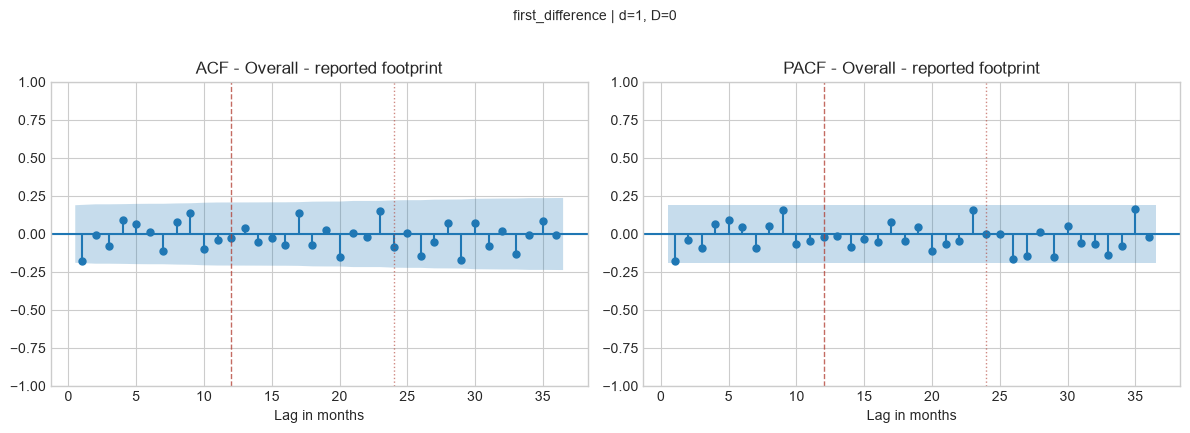

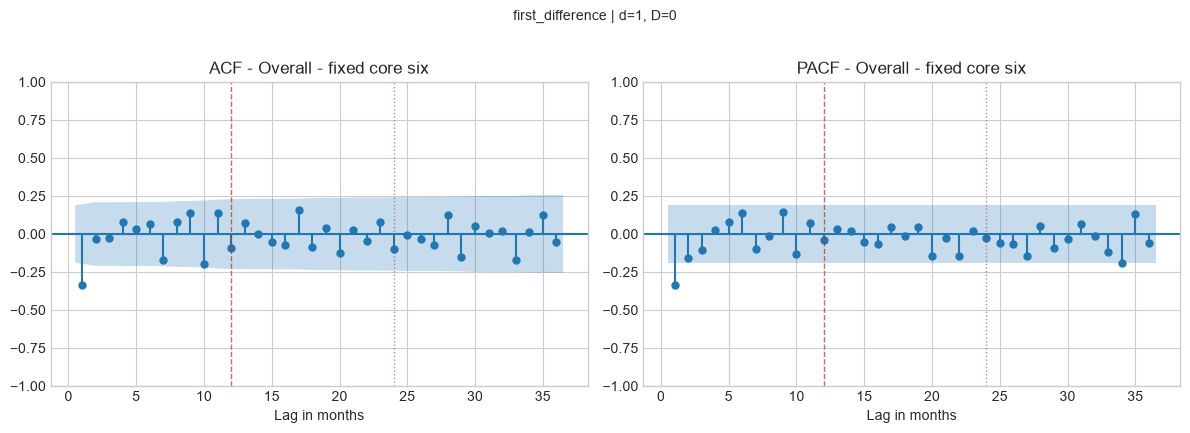

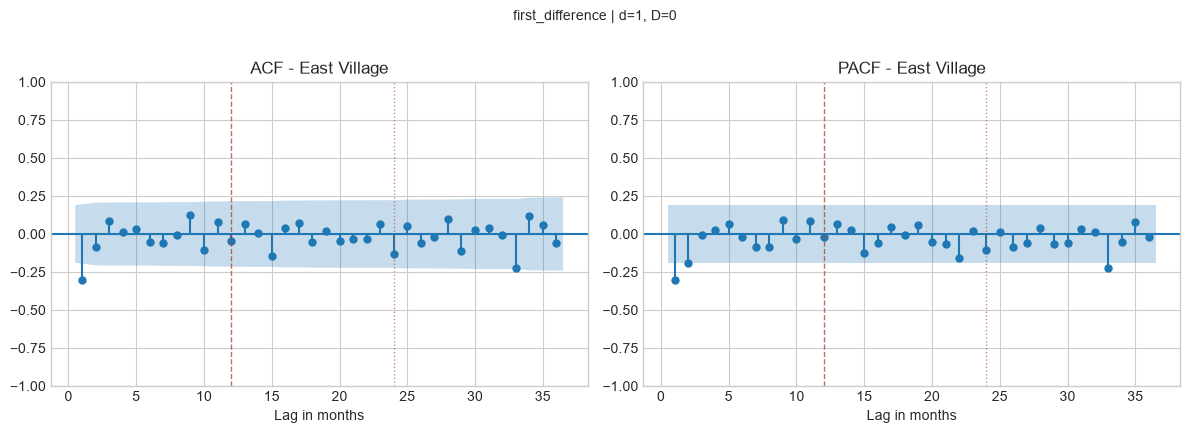

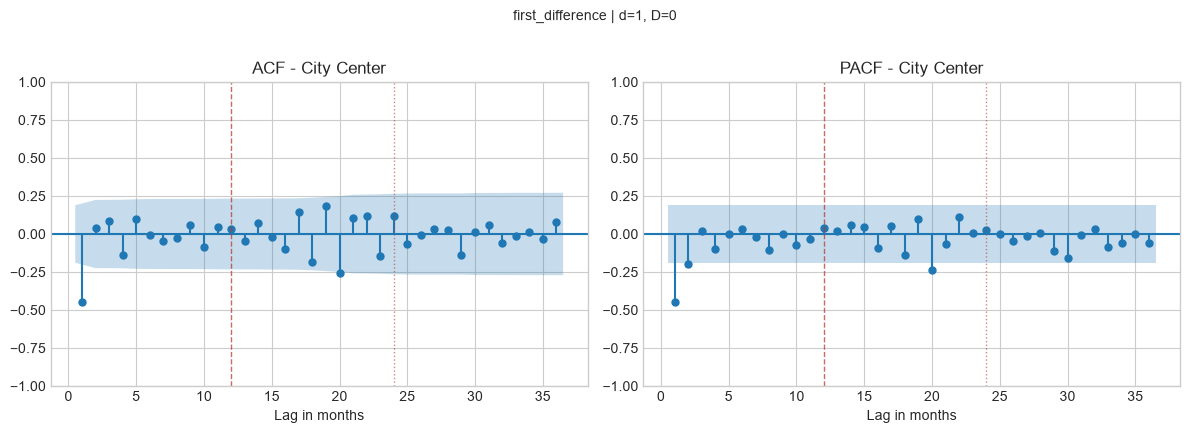

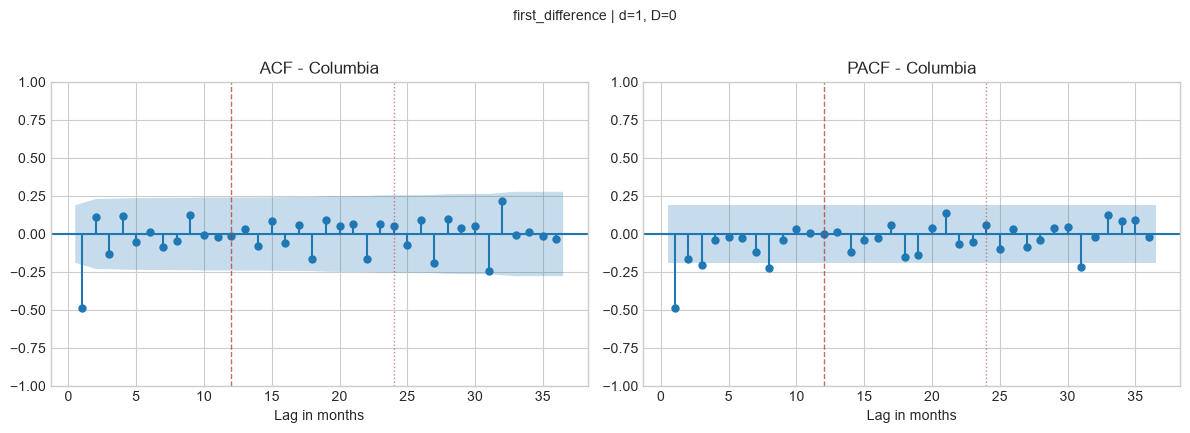

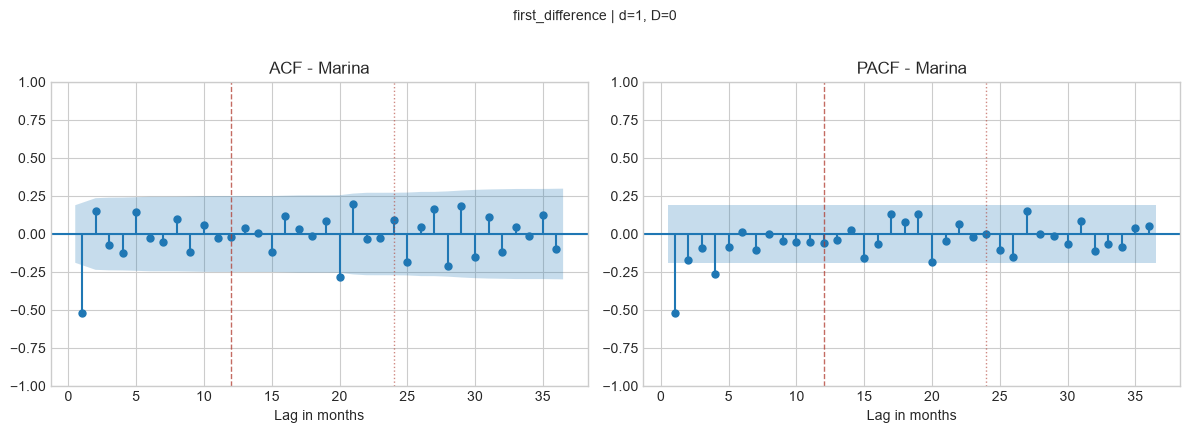

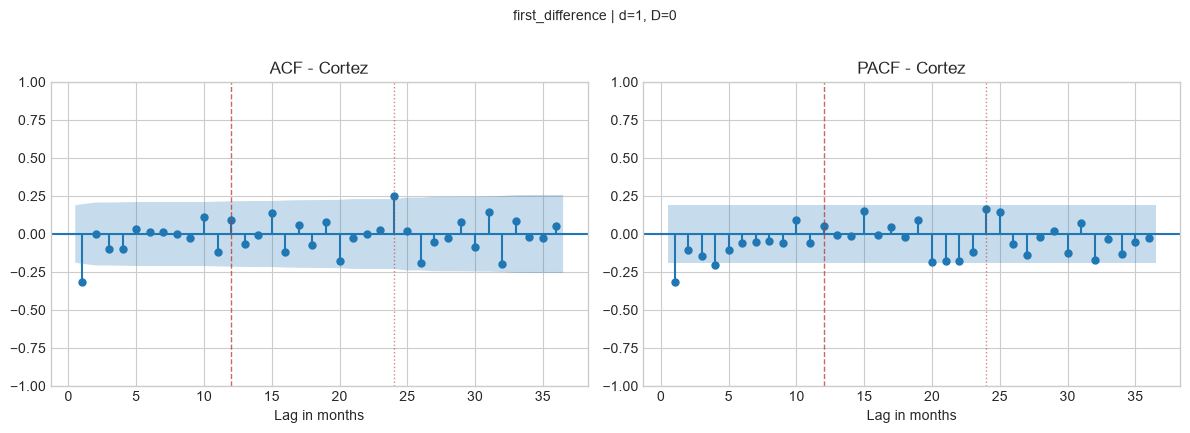

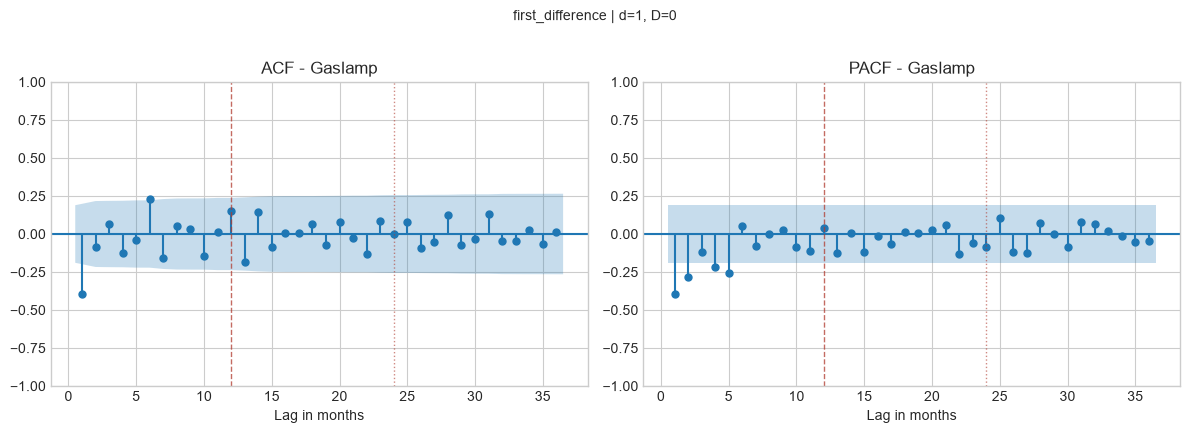

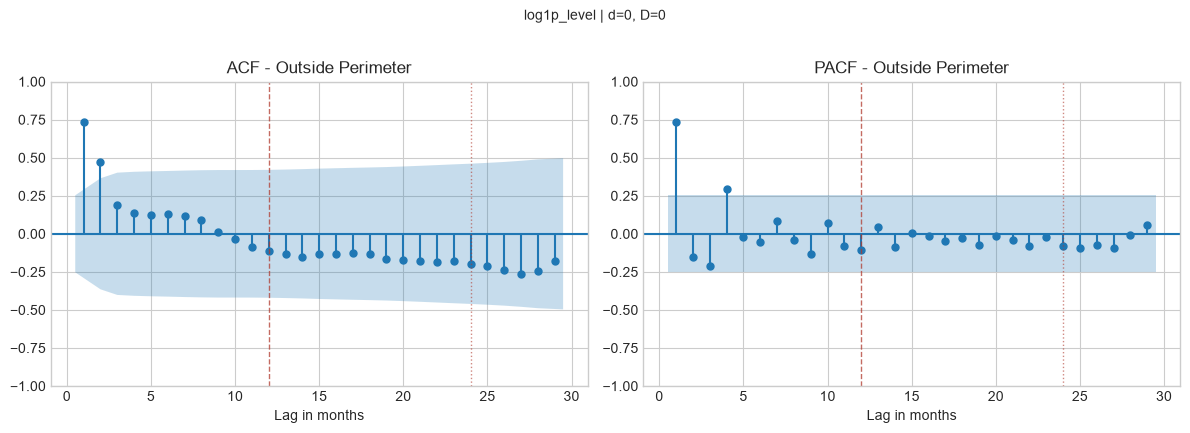

Saved 9 ACF/PACF figures to figures/task4_4


In [7]:
def safe_slug(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")


for name, choice in selected.items():
    values = choice["series_values"]
    max_lag = min(36, len(values) // 2 - 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    plot_acf(values, lags=max_lag, alpha=0.05, zero=False, ax=axes[0])
    plot_pacf(values, lags=max_lag, alpha=0.05, zero=False, method="ywm", ax=axes[1])
    axes[0].set_title(f"ACF - {name}")
    axes[1].set_title(f"PACF - {name}")
    for axis in axes:
        axis.axvline(12, color="#b03a2e", linestyle="--", linewidth=1, alpha=0.75)
        axis.axvline(24, color="#b03a2e", linestyle=":", linewidth=1, alpha=0.6)
        axis.set_xlabel("Lag in months")
    fig.suptitle(f"{choice['transformation']} | d={choice['d']}, D={choice['D']}", y=1.02, fontsize=10)
    fig.tight_layout()
    output_path = FIGURE_DIR / f"acf_pacf_{safe_slug(name)}.png"
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()

print(f"Saved {len(selected)} ACF/PACF figures to {FIGURE_DIR}")

## 7. Forecasting implications

In [8]:
summary_lines = ["### Series-level ARIMA/SARIMA screening"]
for _, row in order_summary.iterrows():
    seasonal = (
        f"seasonal candidate (P,D,Q,12)=({int(row.P)},{int(row.D)},{int(row.Q)},12)"
        if row.P or row.Q or row.D
        else "no seasonal AR/MA term is indicated by the lag-12 screen"
    )
    summary_lines.append(
        f"- **{row['series']}**: `{row.transformation}`; candidate nonseasonal "
        f"(p,d,q)=({int(row.p)},{int(row.d)},{int(row.q)}); {seasonal}."
    )
display(Markdown("\n".join(summary_lines)))

print("These orders are starting values only. Task 7 must compare neighboring specifications")
print("using rolling-origin validation, residual diagnostics, and forecast error rather than")
print("selecting a model from ACF/PACF plots alone.")

### Series-level ARIMA/SARIMA screening
- **City Center**: `first_difference`; candidate nonseasonal (p,d,q)=(2,1,1); no seasonal AR/MA term is indicated by the lag-12 screen.
- **Columbia**: `first_difference`; candidate nonseasonal (p,d,q)=(1,1,1); no seasonal AR/MA term is indicated by the lag-12 screen.
- **Cortez**: `first_difference`; candidate nonseasonal (p,d,q)=(1,1,1); no seasonal AR/MA term is indicated by the lag-12 screen.
- **East Village**: `first_difference`; candidate nonseasonal (p,d,q)=(2,1,1); no seasonal AR/MA term is indicated by the lag-12 screen.
- **Gaslamp**: `first_difference`; candidate nonseasonal (p,d,q)=(2,1,1); no seasonal AR/MA term is indicated by the lag-12 screen.
- **Marina**: `first_difference`; candidate nonseasonal (p,d,q)=(1,1,1); no seasonal AR/MA term is indicated by the lag-12 screen.
- **Outside Perimeter**: `log1p_level`; candidate nonseasonal (p,d,q)=(1,0,2); no seasonal AR/MA term is indicated by the lag-12 screen.
- **Overall - fixed core six**: `first_difference`; candidate nonseasonal (p,d,q)=(1,1,1); no seasonal AR/MA term is indicated by the lag-12 screen.
- **Overall - reported footprint**: `first_difference`; candidate nonseasonal (p,d,q)=(0,1,0); no seasonal AR/MA term is indicated by the lag-12 screen.

These orders are starting values only. Task 7 must compare neighboring specifications
using rolling-origin validation, residual diagnostics, and forecast error rather than
selecting a model from ACF/PACF plots alone.


## 8. Missing-data and robustness sensitivity

In [9]:
sensitivity = tests.loc[
    tests["stage"].isin(["forecast_stationary", "forecast_stationary_pre_first_gap_sensitivity"]),
    ["series", "stage", "n", "adf_pvalue", "kpss_pvalue", "conclusion"],
].copy()
display(sensitivity.round(4))

comparison = sensitivity.pivot(index="series", columns="stage", values="conclusion")
if "forecast_stationary_pre_first_gap_sensitivity" in comparison.columns:
    comparison["unchanged_call"] = (
        comparison["forecast_stationary"]
        == comparison["forecast_stationary_pre_first_gap_sensitivity"]
    )
display(comparison)

,series,stage,n,adf_pvalue,kpss_pvalue,conclusion
4,Overall - reported footprint,forecast_stationary,107,0.0000,0.1,consensus_stationary
5,Overall - reported footprint,forecast_stationary_pre_first_gap_sensitivity,101,0.0000,0.1,consensus_stationary
10,Overall - fixed core six,forecast_stationary,107,0.0068,0.1,consensus_stationary
11,Overall - fixed core six,forecast_stationary_pre_first_gap_sensitivity,101,0.0061,0.1,consensus_stationary
16,East Village,forecast_stationary,107,0.0000,0.1,consensus_stationary
17,East Village,forecast_stationary_pre_first_gap_sensitivity,101,0.0000,0.1,consensus_stationary
22,City Center,forecast_stationary,107,0.0000,0.1,consensus_stationary
23,City Center,forecast_stationary_pre_first_gap_sensitivity,101,0.0000,0.1,consensus_stationary
28,Columbia,forecast_stationary,107,0.0000,0.1,consensus_stationary
29,Columbia,forecast_stationary_pre_first_gap_sensitivity,101,0.0000,0.1,consensus_stationary


stage,forecast_stationary,forecast_stationary_pre_first_gap_sensitivity,unchanged_call
series,,,
City Center,consensus_stationary,consensus_stationary,True
Columbia,consensus_stationary,consensus_stationary,True
Cortez,consensus_stationary,consensus_stationary,True
East Village,consensus_stationary,consensus_stationary,True
Gaslamp,consensus_stationary,consensus_stationary,True
Marina,consensus_stationary,consensus_stationary,True
Outside Perimeter,consensus_stationary,consensus_stationary,True
Overall - fixed core six,consensus_stationary,consensus_stationary,True
Overall - reported footprint,consensus_stationary,consensus_stationary,True


## 9. Limitations and handoff notes

- ADF and KPSS have different null hypotheses and limited power in short, break-prone series.
  Mixed results are retained rather than forced into a binary conclusion.
- The Assignment 4 series contain known methodology changes and COVID-era disruption. Differencing
  can stabilize means but does not erase the substantive break structure documented in Task 4.3.
- The reported-footprint aggregate changes coverage when `Outside Perimeter` begins in 2021; the
  fixed-core-six series remains the preferred stable-geography aggregate for forecasting comparisons.
- Interpolation exists only to maintain a regular monthly analysis grid. The forecasting CSV flags
  both directly interpolated rows and transformed values that depend on an interpolated observation.
- ACF/PACF orders are diagnostic starting points. Final model selection belongs to Task 7 and must
  use time-series cross-validation, information criteria, and residual white-noise checks.

**Deliverables:** `Stationarity_Autocorrelation.ipynb`, `data/StationarityTests.csv`,
`data/AutocorrelationDiagnostics.csv`, and `data/AdjustedTimeSeries_Forecasting.csv`.

In [10]:
SOURCE_HASH_AFTER = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert SOURCE_HASH_AFTER == SOURCE_HASH_BEFORE, "Canonical source CSV changed during analysis"
assert not forecast_data.duplicated(["series", "date"]).any()
assert forecast_data["stationary_value"].notna().all()
assert set(forecast_data["stationarity_conclusion"]) == {"consensus_stationary"}
assert TEST_OUTPUT.exists() and TEST_OUTPUT.stat().st_size > 0
assert AC_OUTPUT.exists() and AC_OUTPUT.stat().st_size > 0
assert FORECAST_OUTPUT.exists() and FORECAST_OUTPUT.stat().st_size > 0
print("Verification passed:")
print("  - canonical source hash unchanged")
print("  - notebook outputs written")
print("  - forecasting rows are unique and non-null")
print("  - all selected forecasting transformations achieve ADF/KPSS consensus")

Verification passed:
  - canonical source hash unchanged
  - notebook outputs written
  - forecasting rows are unique and non-null
  - all selected forecasting transformations achieve ADF/KPSS consensus
